# Decision Tree (MI + RFECV feature selection) — NIDS (CIC-UNSW-NB15-2024)

Variant of the baseline Decision Tree notebook with an added **supervised feature-selection** stage (2.8–2.9): Mutual Information ranking + RFECV (balanced RandomForest, macro-F1), fit **train-only**, reducing the 44 redundancy-pruned features to the CV-optimal subset (≈36).

Compare against the baseline `decision_tree.ipynb` (44 features, macro-F1 0.5338). Expectation: near-identical macro-F1 with fewer, relevance-justified features — the RFECV CV curve is flat past ~17 features, so this buys rigour/parsimony/interpretability, not accuracy.

## 1. Data Collection
_Sources & Quality_

In [1]:
import pandas as pd
import numpy as np

# Features and labels are two parallel files, row-aligned by position (no shared key).
X = pd.read_csv("Resource/CIC-UNSW-Data.csv")
y = pd.read_csv("Resource/CIC-UNSW-Label.csv")

print("Features:", X.shape)
print("Labels:  ", y.shape)
print("Rows aligned:", len(X) == len(y))
X.head()

Features: (447915, 76)
Labels:   (447915, 1)
Rows aligned: True


,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,214392,9,21,388.0,24564.0,194.0,0.0,43.111111,85.545959,1460.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2376792,9,3,752.0,0.0,188.0,0.0,83.555556,99.084700,0.0,...,4,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,131350,10,3,7564.0,0.0,1460.0,0.0,756.400000,690.497277,0.0,...,6,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,164796,6,3,770.0,0.0,385.0,0.0,128.333333,198.813145,0.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,163418,6,3,400.0,0.0,200.0,0.0,66.666667,103.279556,0.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data Preparation
_Clean & Transform_

### 2.1 Check for duplicates

In [2]:
# Check duplicates on features + label together, so we only count rows that are
# truly identical (same flow AND same class).
df = pd.concat([X, y], axis=1)

n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
print(f"Duplicate share: {n_dup / len(df) * 100:.2f}%")

Duplicate rows: 141742
Duplicate share: 31.64%


### 2.2 Drop duplicates

In [3]:
# Drop on the combined frame so features and labels stay aligned, then split back.
df = df.drop_duplicates().reset_index(drop=True)

X = df[X.columns]
y = df[y.columns]

print("After dropping duplicates:")
print("Features:", X.shape)
print("Labels:  ", y.shape)
print("Duplicates remaining:", df.duplicated().sum())

After dropping duplicates:
Features: (306173, 76)
Labels:   (306173, 1)
Duplicates remaining: 0


### 2.3 Class distribution

Inspect the target balance across the 10 classes (Normal + 9 attack families). This frames the two key decisions that follow: a **stratified** split and **imbalance handling**.

               attack   count  percent
label                                 
0              Benign  225003   73.489
1            Analysis     385    0.126
2            Backdoor     452    0.148
3                 DoS    4412    1.441
4            Exploits   30910   10.096
5             Fuzzers   26395    8.621
6             Generic    4496    1.468
7      Reconnaissance   12031    3.929
8           Shellcode    1848    0.604
9               Worms     241    0.079


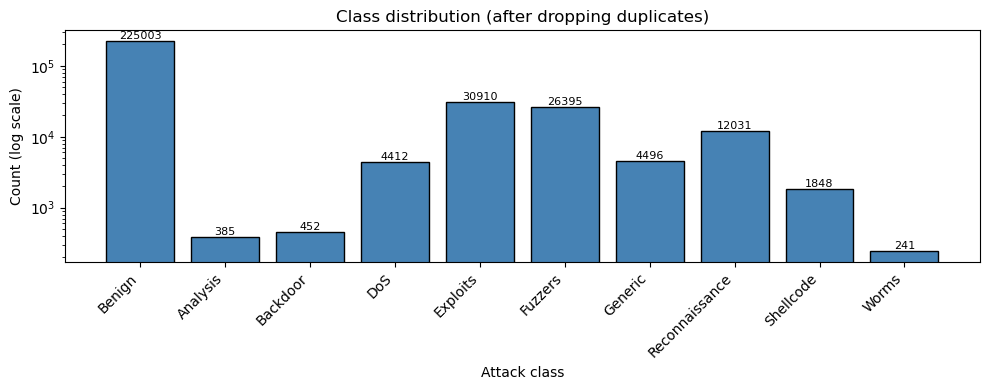

In [4]:
import matplotlib.pyplot as plt

# Official label mapping (not stored in the CSVs). Attack families are alphabetical, Benign = 0.
LABELS = {
    0: "Benign", 1: "Analysis", 2: "Backdoor", 3: "DoS", 4: "Exploits",
    5: "Fuzzers", 6: "Generic", 7: "Reconnaissance", 8: "Shellcode", 9: "Worms",
}

# Counts and percentage share per class
counts = y["Label"].value_counts().sort_index()
dist = pd.DataFrame({
    "attack": [LABELS[i] for i in counts.index],
    "count": counts.values,
    "percent": (counts.values / counts.sum() * 100).round(3),
}, index=counts.index)
dist.index.name = "label"
print(dist)

# Log scale: with ~80% Benign vs ~0.05% rarest (Worms), a linear axis hides the rare classes.
plt.figure(figsize=(10, 4))
bars = plt.bar([LABELS[i] for i in counts.index], counts.values,
               color="steelblue", edgecolor="black")
plt.yscale("log")
plt.title("Class distribution (after dropping duplicates)")
plt.xlabel("Attack class")
plt.ylabel("Count (log scale)")
plt.xticks(rotation=45, ha="right")
plt.bar_label(bars, fontsize=8)
plt.tight_layout()
plt.show()

### 2.4 Variance check

A feature with only one unique value (zero variance) carries no information — it can't split anything in a tree. Identify these constant columns now; they become drop candidates in 2.6.

In [5]:
# A constant feature has exactly one unique value across all rows (zero variance).
nunique = X.nunique()
zero_var_cols = nunique[nunique <= 1].index.tolist()

print(f"Total features:           {X.shape[1]}")
print(f"Zero-variance (constant): {len(zero_var_cols)}\n")
for c in zero_var_cols:
    print(f"  {c:<22} -> constant value = {X[c].iloc[0]}")

Total features:           76
Zero-variance (constant): 9

  Bwd PSH Flags          -> constant value = 0
  Fwd URG Flags          -> constant value = 0
  Bwd URG Flags          -> constant value = 0
  URG Flag Count         -> constant value = 0
  CWR Flag Count         -> constant value = 0
  ECE Flag Count         -> constant value = 0
  Fwd Bytes/Bulk Avg     -> constant value = 0
  Fwd Packet/Bulk Avg    -> constant value = 0
  Fwd Bulk Rate Avg      -> constant value = 0


### 2.5 Correlation

CIC flow features include many near-duplicate measurements (e.g. packet-length vs. segment-size stats). Highly correlated features add redundancy without new signal. Plot the correlation matrix and list pairs above a threshold as drop candidates. The constant columns from 2.4 are excluded here (their correlation is undefined).

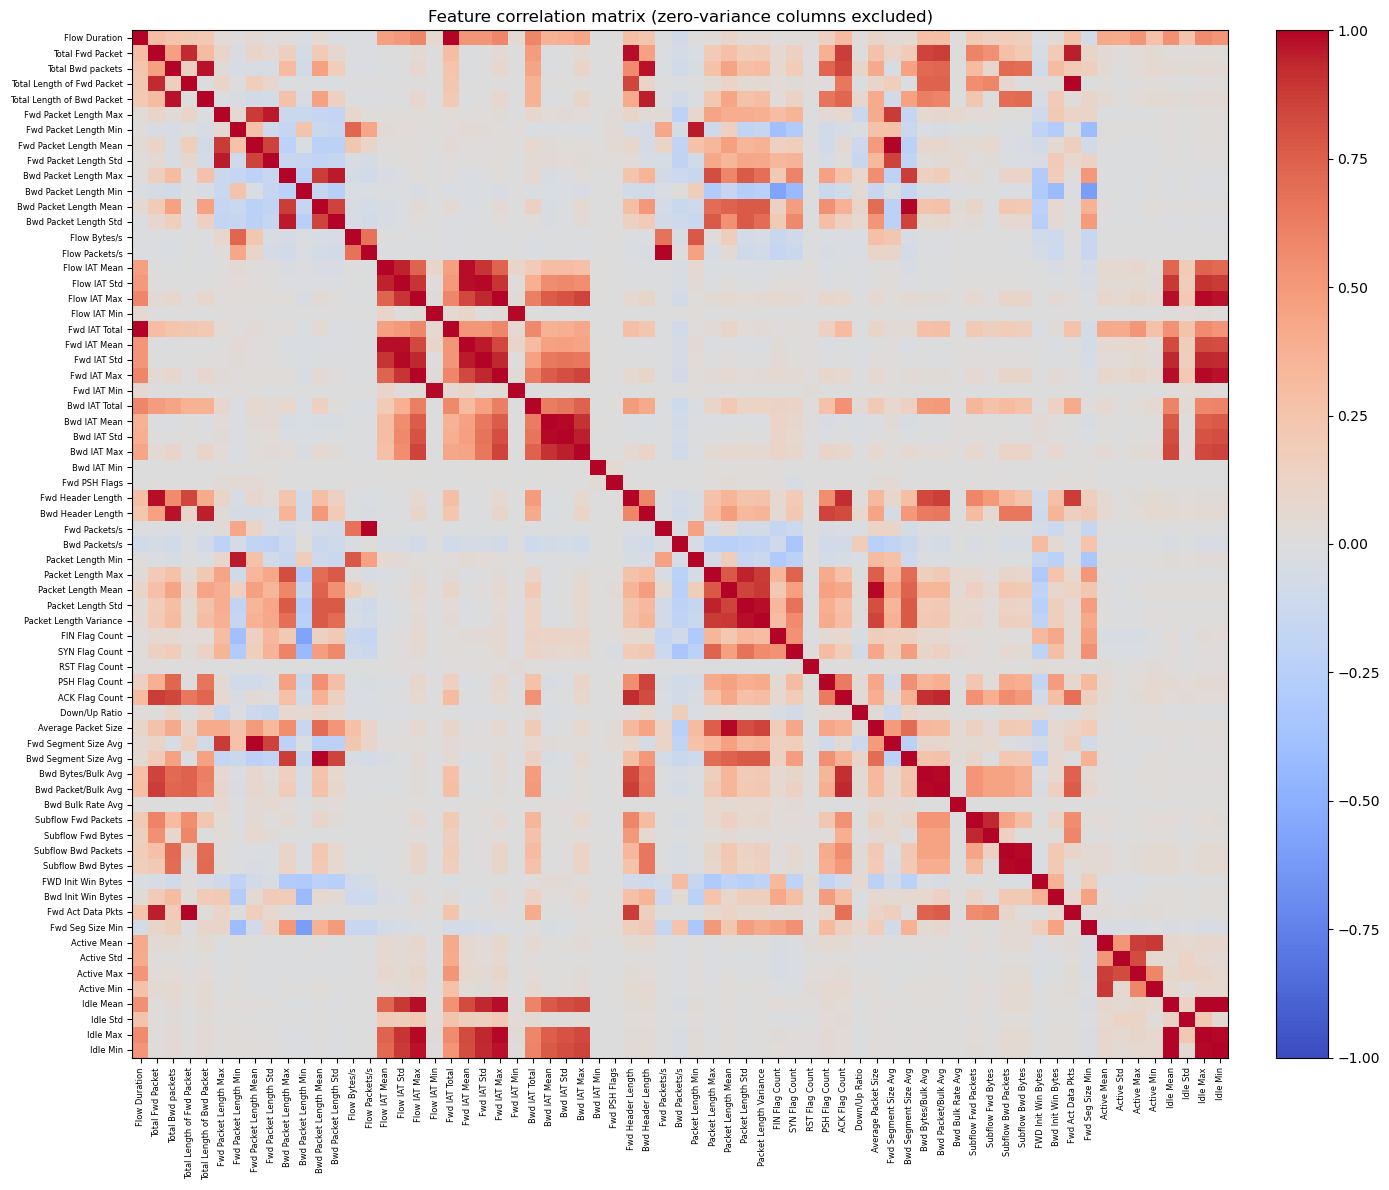

In [6]:
# Correlation among informative features only (constant columns -> undefined correlation).
features = X.drop(columns=zero_var_cols)
corr = features.corr()

plt.figure(figsize=(14, 12))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr)), corr.columns, fontsize=6)
plt.title("Feature correlation matrix (zero-variance columns excluded)")
plt.tight_layout()
plt.show()

In [7]:
# List highly correlated feature pairs (upper triangle only, to avoid duplicates).
THRESHOLD = 0.95

upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"})
)
high_pairs = high_pairs[high_pairs["abs_corr"] >= THRESHOLD].sort_values(
    "abs_corr", ascending=False
).reset_index(drop=True)

print(f"Highly correlated pairs (|r| >= {THRESHOLD}): {len(high_pairs)}\n")
print(high_pairs.to_string(index=False))

Highly correlated pairs (|r| >= 0.95): 31

                 feature_1                  feature_2  abs_corr
    Fwd Packet Length Mean       Fwd Segment Size Avg  1.000000
    Bwd Packet Length Mean       Bwd Segment Size Avg  1.000000
            Flow Packets/s              Fwd Packets/s  0.999304
             Flow Duration              Fwd IAT Total  0.999037
              Flow IAT Max                Fwd IAT Max  0.997462
                 Idle Mean                   Idle Min  0.997389
                 Idle Mean                   Idle Max  0.995172
Total Length of Fwd Packet          Fwd Act Data Pkts  0.993241
        Packet Length Mean        Average Packet Size  0.991194
              Flow IAT Std                Fwd IAT Std  0.988993
        Bwd Bytes/Bulk Avg        Bwd Packet/Bulk Avg  0.988857
              Flow IAT Max                   Idle Max  0.988439
       Subflow Bwd Packets          Subflow Bwd Bytes  0.988309
                  Idle Max                   Idle Min  0.9863

### 2.6 Drop uninformative & redundant features

Now act on the evidence gathered above:
- **Zero-variance** columns from 2.4 (`zero_var_cols`) — no signal.
- **Redundant** columns from 2.5 — for each pair with |r| ≥ 0.95, keep the first feature (by column order) and drop the later one.

The exact drop list is printed before applying, so every removed feature is traceable to its evidence.

In [8]:
# Redundant: a column is dropped if it correlates >= THRESHOLD with any earlier-kept column
# (upper triangle => keeps the first feature of each correlated group).
redundant_cols = [c for c in upper.columns if (upper[c] >= THRESHOLD).any()]

# Combine both evidence-based drop sets (de-duplicated, order preserved).
drop_cols = list(dict.fromkeys(zero_var_cols + redundant_cols))

print(f"Zero-variance to drop ({len(zero_var_cols)}):")
print(" ", zero_var_cols, "\n")
print(f"Redundant |r|>={THRESHOLD} to drop ({len(redundant_cols)}):")
print(" ", redundant_cols, "\n")
print(f"Total unique columns to drop: {len(drop_cols)}")

# Apply the drop, keeping X and y aligned (y is untouched).
X = X.drop(columns=drop_cols)
print(f"\nFeatures remaining: {X.shape[1]} (from 76)")

Zero-variance to drop (9):
  ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count', 'Fwd Bytes/Bulk Avg', 'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg'] 

Redundant |r|>=0.95 to drop (23):
  ['Total Length of Bwd Packet', 'Fwd Packet Length Std', 'Bwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Std', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Packet Length Min', 'Packet Length Variance', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg', 'Bwd Packet/Bulk Avg', 'Subflow Bwd Bytes', 'Fwd Act Data Pkts', 'Idle Mean', 'Idle Max', 'Idle Min'] 

Total unique columns to drop: 32

Features remaining: 44 (from 76)


### 2.7 Stratified train/test split

Split **before** any resampling so nothing leaks across train/test. `stratify=y` preserves each class's proportion in both splits — essential here, since the rarest classes (Worms = 246, Analysis = 385) would otherwise risk being absent from one side.

No feature scaling is applied: the Decision Tree is scale-invariant, so a scaler would add nothing (scaling is reserved for the non-tree baselines later).

In [9]:
from sklearn.model_selection import train_test_split

y_series = y["Label"]  # sklearn wants a 1-D target

X_train, X_test, y_train, y_test = train_test_split(
    X, y_series,
    test_size=0.2,
    random_state=42,
    stratify=y_series,
)

print("Train:", X_train.shape, "| Test:", X_test.shape, "\n")

# Confirm stratification held the class proportions in both splits.
check = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index().round(4),
    "test":  y_test.value_counts(normalize=True).sort_index().round(4),
})
check.index = [LABELS[i] for i in check.index]
print(check)

Train: (244938, 44) | Test: (61235, 44) 

                 train    test
Benign          0.7349  0.7349
Analysis        0.0013  0.0013
Backdoor        0.0015  0.0015
DoS             0.0144  0.0144
Exploits        0.1010  0.1010
Fuzzers         0.0862  0.0862
Generic         0.0147  0.0147
Reconnaissance  0.0393  0.0393
Shellcode       0.0060  0.0060
Worms           0.0008  0.0008


### 2.8 Supervised feature selection (relevance)

Steps 2.4–2.6 removed features by **redundancy** (constant, or |r| ≥ 0.95) — an *unsupervised* prune that never asks whether a feature is relevant to the attack label. Now add a **supervised** step, fit on the **training split only** (so nothing leaks from the test set):

- **Mutual Information** — a *non-linear* relevance score per feature (how much knowing the feature reduces uncertainty about the class).
- **RFECV** — Recursive Feature Elimination with cross-validation, using a balanced RandomForest scored on **macro-F1**; it *cross-validates the number of features* instead of guessing it.

Both run on a stratified train subsample for speed (rankings are stable). A third method (mRMR) was checked separately and converges on the same set once a non-linear relevance metric is used — so the selection is a **three-method consensus**. Expect the CV curve to be **flat** past ~17 features: this step buys rigour, parsimony and interpretability (and a cleaner set for later SHAP), not a large accuracy jump — the accuracy lever remains imbalance handling.

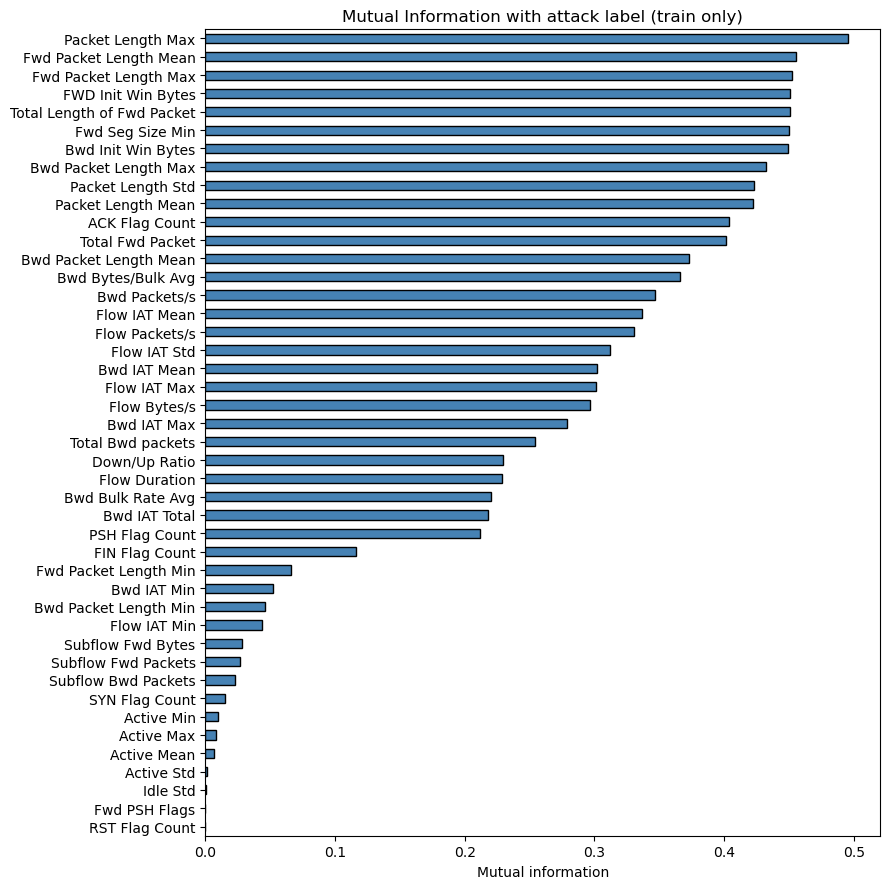

Packet Length Max             0.4955
Fwd Packet Length Mean        0.4557
Fwd Packet Length Max         0.4525
FWD Init Win Bytes            0.4510
Total Length of Fwd Packet    0.4506
Fwd Seg Size Min              0.4502
Bwd Init Win Bytes            0.4492
Bwd Packet Length Max         0.4320
Packet Length Std             0.4234
Packet Length Mean            0.4224
ACK Flag Count                0.4037
Total Fwd Packet              0.4012
Bwd Packet Length Mean        0.3730
Bwd Bytes/Bulk Avg            0.3657
Bwd Packets/s                 0.3470
Flow IAT Mean                 0.3364
Flow Packets/s                0.3302
Flow IAT Std                  0.3120
Bwd IAT Mean                  0.3023
Flow IAT Max                  0.3009
Flow Bytes/s                  0.2965
Bwd IAT Max                   0.2789
Total Bwd packets             0.2546
Down/Up Ratio                 0.2296
Flow Duration                 0.2287
Bwd Bulk Rate Avg             0.2202
Bwd IAT Total                 0.2182
P

In [10]:
from sklearn.feature_selection import mutual_info_classif

# Mutual Information: non-linear relevance of each feature to the attack label.
# Computed on TRAIN only; subsampled for speed (rankings are stable).
mi_sample_n = 80000
if len(X_train) > mi_sample_n:
    mi_idx = (y_train.groupby(y_train, group_keys=False)
                     .apply(lambda s: s.sample(frac=mi_sample_n / len(X_train), random_state=42)).index)
    X_mi, y_mi = X_train.loc[mi_idx], y_train.loc[mi_idx]
else:
    X_mi, y_mi = X_train, y_train

mi = mutual_info_classif(X_mi, y_mi, discrete_features=False, random_state=42)
mi_rank = pd.Series(mi, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 9))
mi_rank.iloc[::-1].plot.barh(color="steelblue", edgecolor="black")
plt.title("Mutual Information with attack label (train only)")
plt.xlabel("Mutual information")
plt.tight_layout()
plt.show()

print(mi_rank.round(4).to_string())

CV-optimal number of features: 36  (selector fit on 49999 rows)


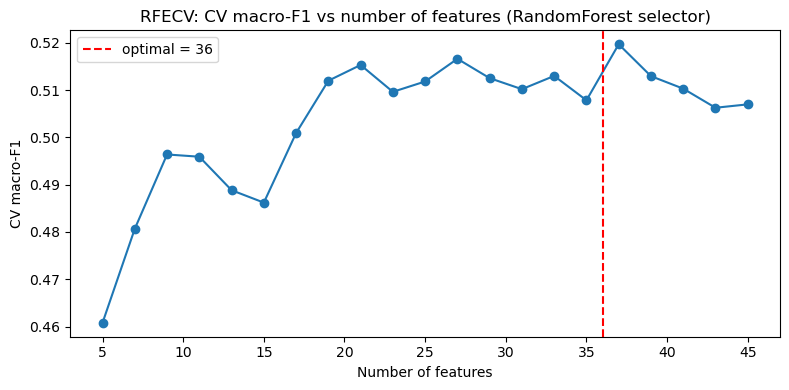

In [11]:
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

# RFECV: recursively eliminate the weakest feature, cross-validating the score at each size.
# Selector = balanced RandomForest, scored on MACRO-F1 (so rare classes count). Train only.
rfe_sample_n = 50000
if len(X_train) > rfe_sample_n:
    rfe_idx = (y_train.groupby(y_train, group_keys=False)
                      .apply(lambda s: s.sample(frac=rfe_sample_n / len(X_train), random_state=42)).index)
    X_rfe, y_rfe = X_train.loc[rfe_idx], y_train.loc[rfe_idx]
else:
    X_rfe, y_rfe = X_train, y_train

selector_est = RandomForestClassifier(
    n_estimators=120, class_weight="balanced", random_state=42, n_jobs=-1)
rfecv = RFECV(
    estimator=selector_est, step=2,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="f1_macro", min_features_to_select=5, n_jobs=-1)
rfecv.fit(X_rfe, y_rfe)

print(f"CV-optimal number of features: {rfecv.n_features_}  (selector fit on {len(X_rfe)} rows)")

# CV curve: macro-F1 vs number of features.
grid = rfecv.cv_results_["mean_test_score"]
n_axis = list(range(rfecv.min_features_to_select,
                    rfecv.min_features_to_select + len(grid) * rfecv.step, rfecv.step))
plt.figure(figsize=(8, 4))
plt.plot(n_axis, grid, marker="o")
plt.axvline(rfecv.n_features_, color="red", ls="--", label=f"optimal = {rfecv.n_features_}")
plt.title("RFECV: CV macro-F1 vs number of features (RandomForest selector)")
plt.xlabel("Number of features")
plt.ylabel("CV macro-F1")
plt.legend()
plt.tight_layout()
plt.show()

### 2.9 Apply the selected feature set

In [12]:
# RFECV's cross-validated optimum is the final feature set.
# The mask was learned on TRAIN only, so applying it to the test split adds no leakage.
selected_features = X_train.columns[rfecv.support_].tolist()
dropped_features  = X_train.columns[~rfecv.support_].tolist()

print(f"Selected {len(selected_features)} features (from {X_train.shape[1]}):")
print(selected_features, "\n")
print(f"Dropped {len(dropped_features)}: {dropped_features}")

# Reduce both splits to the selected features (y untouched, alignment preserved).
X_train = X_train[selected_features]
X_test  = X_test[selected_features]
print("\nFinal shapes -> Train:", X_train.shape, "| Test:", X_test.shape)

Selected 36 features (from 44):
['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Max', 'Bwd IAT Min', 'Bwd Packets/s', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Down/Up Ratio', 'Bwd Bytes/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Seg Size Min'] 

Dropped 8: ['Fwd PSH Flags', 'SYN Flag Count', 'RST Flag Count', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Std']

Final shapes -> Train: (244938, 36) | Test: (61235, 36)


## 3. Model Selection
_Algorithm Choice_

Baseline classifier: **Decision Tree**. `class_weight='balanced'` is the imbalance baseline — it weights each class inversely to its frequency, so the rare attack classes (Worms, Analysis, Backdoor) aren't ignored in favour of the 80% Benign majority. Left unpruned for now; tuning happens in Stage 6.

In [13]:
from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier(
    class_weight="balanced",  # weights inversely proportional to class frequency
    random_state=42,
)
clf

DecisionTreeClassifier(class_weight='balanced', random_state=42)

## 4. Model Training
_Learning Process_

Fit on the training split only.

In [14]:
clf.fit(X_train, y_train)

print("Training complete.")
print("Tree depth:", clf.get_depth())
print("Leaf count:", clf.get_n_leaves())

Training complete.
Tree depth: 53
Leaf count: 23128


## 5. Model Evaluation
_Test Performance_

With 80% Benign, plain accuracy is misleading — a model predicting "Benign" always scores ~80%. The metrics that matter are **macro-F1** (averages all classes equally, so rare classes count) and the **per-class precision/recall**. The confusion matrix then shows exactly which attacks get missed or confused.

### 5.1 Metrics

In [15]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

y_pred  = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)   # class probabilities, needed for ROC-AUC

labels_sorted = sorted(y_test.unique())
target_names = [LABELS[i] for i in labels_sorted]

# 'weighted' = the "normal" average (each class weighted by its support, so dominated
# by Benign); 'macro' = every class counts equally, so rare attacks matter just as much.
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
print(f"Accuracy    : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}   (macro, One-vs-Rest)\n")

print(f"{'':<12}{'weighted':>10}{'macro':>10}")
for name, metric in [("Precision", precision_score), ("Recall", recall_score), ("F1-score", f1_score)]:
    w = metric(y_test, y_pred, average="weighted", zero_division=0)
    m = metric(y_test, y_pred, average="macro", zero_division=0)
    note = "   <- macro F1 = primary metric" if name == "F1-score" else ""
    print(f"{name:<12}{w:>10.4f}{m:>10.4f}{note}")

print()
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

Accuracy    : 0.8847
ROC-AUC     : 0.7556   (macro, One-vs-Rest)

              weighted     macro
Precision       0.8851    0.5361
Recall          0.8847    0.5282
F1-score        0.8849    0.5316   <- macro F1 = primary metric

                precision    recall  f1-score   support

        Benign     0.9750    0.9738    0.9744     45001
      Analysis     0.2812    0.2338    0.2553        77
      Backdoor     0.5443    0.4778    0.5089        90
           DoS     0.3252    0.3488    0.3366       883
      Exploits     0.7213    0.7208    0.7210      6182
       Fuzzers     0.6400    0.6342    0.6371      5279
       Generic     0.7199    0.7519    0.7356       899
Reconnaissance     0.5756    0.5869    0.5812      2406
     Shellcode     0.2090    0.2000    0.2044       370
         Worms     0.3696    0.3542    0.3617        48

      accuracy                         0.8847     61235
     macro avg     0.5361    0.5282    0.5316     61235
  weighted avg     0.8851    0.8847    0

### 5.2 Confusion matrix

Raw counts across the 10 classes (Benign-dominated). Per-class recall is reported numerically in 5.1.

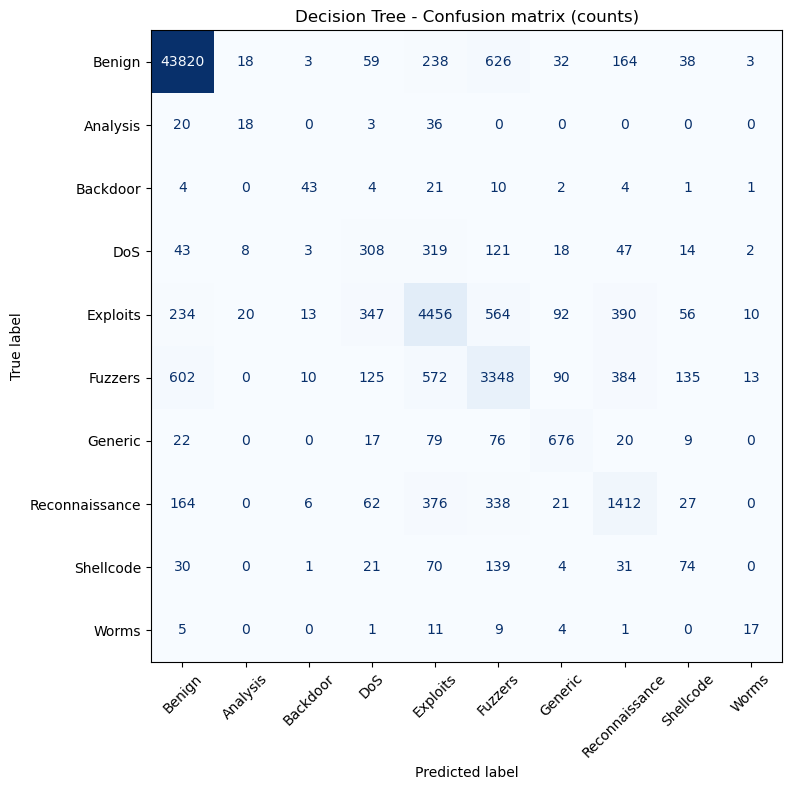

In [16]:
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("Decision Tree - Confusion matrix (counts)")
plt.tight_layout()
plt.show()